# 1. DAILY RSI(2) MEAN REVERSION - HYPOTHESIS DEFINITION & BASELINE BACKTEST

This notebook formulates the quantitative hypothesis and establishes the baseline backtest for the **Alphaca RSI(2) Mean Reversion** strategy on **Multiple** daily bars.

### 1.1 CORE QUANTITATIVE HYPOTHESIS
The strategy exploits a structural property of equity index markets identified in our Exploratory Data Analysis:
- **Macro Trend Drift**: The Nasdaq-100 exhibits a persistent multi-decade upward drift (~10.9% CAGR since 1999).
- **Short-Term Micro Reversal**: Daily returns exhibit negative autocorrelation (Lag 1 ACF = -0.058) and a sub-diffusive Hurst exponent ($H = 0.48 < 0.50$).
- **The Core Premise**: When an asset in a macro bull market (`Close > SMA(between 190 and 250)`) experiences severe, sudden selling pressure (`RSI(2) < between 15 and 22`), institutional liquidity providers step in to absorb retail stop-losses and panics. The resulting bounce generates an asymmetric, high-probability mean-reverting edge over the subsequent 2 to 5 sessions.

### 1.2 FROZEN STRATEGY RULES
| Rule Component | Specification |
| :--- | :--- |
| **Instrument** | Multiple, Daily bars (split/dividend adjusted) |
| **Trend Filter** | `Close[t-1] > SMA(between 190 and 250)[t-1]` (evaluated at day $t-1$ close) |
| **Entry Trigger** | `RSI(2)[t-1] < between 15 and 22` (Wilder smoothing, evaluated at day $t-1$ close) |
| **Execution** | Buy at **OPEN** of day $t$ with slippage cost: `Entry = Open[t] * (1 + 0.0005)` |
| **Exit Trigger** | Two consecutive green candles: `Close[t-1] > Open[t-1]` AND `Close[t-2] > Open[t-2]` |
| **Exit Execution** | Sell at **OPEN** of day $t$ with slippage cost: `Exit = Open[t] * (1 - 0.0005)` |
| **Direction** | Long only, no price stop loss |
| **Trading Costs** | 5 bps per side (0.05% per side = 10 bps round-trip), zero commission |
| **Position Sizing** | (a) **Capital Sizing**: 100% equity per trade<br>(b) **ATR Risk Sizing**: 1% risk per trade with 2x ATR(14) stop, capped at 100% |

### 1.3 PROVENANCE & ADAPTATION
- **Academic / Practitioner Origin**: Developed by Larry Connors & Cesar Alvarez (*Short Term Trading Strategies That Work*, 2008).
- **Alphaca Refinement**: Alphaca adapted the exit logic from a fixed MA(5) cross to an agile two-consecutive-green-candles price-action exit, increasing trade velocity and reducing overnight drawdown exposure.

### 01-4 STRATEGY PARAMETERS

In [1]:
VARIANT = "v1_nas100" # only base variants 

## 2. IMPORTS AND CONFIG

In [2]:
%pip install pandas_market_calendars
import os
import sys
import json
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Paths ----
def find_upwards(name, start=None, must_be_dir=True):
    """Sube desde start (cwd por defecto) y devuelve la primera carpeta
    que contiene `name`. Devuelve esa carpeta contenedora."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"No encontré '{name}' subiendo desde {here}")

EDGE_DIR    = find_upwards('variants')                  # carpeta del edge, cualquier nombre
utils_path  = str(find_upwards('utils') / 'utils')      # research_development/utils
engine_path = str(EDGE_DIR)
engine_dir  = str(EDGE_DIR / 'rsi2_engine')

for p in (utils_path, engine_path, engine_dir):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics, plot_equity_curve
from metrics import sharpe_ratio, max_drawdown
import rsi2_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)   # reinicia ENGINE_DEFAULTS: nada se filtra entre variantes y recarga el motor si lo editaste

variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), \
    f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
SMA_LEN    = cfg["params"]["sma_len"]
RSI_THR    = cfg["params"]["rsi_thr"]
EXIT_MODE  = cfg["params"]["exit_mode"]
SLIP_BPS   = cfg["params"]["slip_bps_per_side"]
SLIP       = SLIP_BPS / 10_000

print("Imports complete.")
print(f"Loaded rsi2_engine from: {eng.__file__}")
print(f"Edge dir: {EDGE_DIR}")
print(f"Variant: {cfg['id']} | {TICKER} | RSI(2) < {RSI_THR:g} | SMA({SMA_LEN}) | exit={EXIT_MODE} | {SLIP_BPS:g} bps/side")
print(f"Data source: {eng.ENGINE_DEFAULTS['data_source']} | swap: {eng.ENGINE_DEFAULTS['financing_bps_per_night']:g} bps/night")
print(f"Run folder: {RUN_DIR}")

Note: you may need to restart the kernel to use updated packages.
Imports complete.
Loaded rsi2_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/RSI2/notebooks/RSI2/rsi2_engine.py
Edge dir: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/RSI2/notebooks/RSI2
Variant: RSI2.us500.v2 | nas100 | RSI(2) < 20 | SMA(230) | exit=2green | 5 bps/side
Data source: csv_intraday | swap: 2 bps/night
Run folder: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/RSI2/notebooks/RSI2/runs/v1_nas100


## 3. LOAD DATA AND IN-SAMPLE / OUT-OF-SAMPLE

In [3]:
# Execution rules and split date come from the variant config (previous cell).
# Daily data: yahoo or csv_intraday, depending on engine_defaults.data_source in the variant YAML.
df_raw = eng.load_data(TICKER, start=DATA_START)

print(len(df_raw), df_raw.index.dayofweek.value_counts().sort_index().to_dict())
print(df_raw.groupby(df_raw.index.year).size().to_dict())

df = eng.prepare(df_raw, sma_len=SMA_LEN)

n_is = int((df.index < OOS_START).sum())
df_is = df.iloc[:n_is].copy()
df_oos = df.iloc[n_is:].copy()
assert len(df_is) > 0 and len(df_oos) > 0, "Check split.oos_start against the history of this ticker."
oos_start = df_oos.index[0]

print("=" * 70)
print("DATA INGESTION & DATASET SPLIT")
print("=" * 70)
print(f"Total Prepared Bars: {len(df):,} ({df.index.min().strftime('%Y-%m-%d')} to {df.index.max().strftime('%Y-%m-%d')})")
print(f"In-Sample (IS, {len(df_is)/len(df)*100:.1f}%): {len(df_is):,} bars ({df_is.index.min().strftime('%Y-%m-%d')} to {df_is.index.max().strftime('%Y-%m-%d')})")
print(f"Out-of-Sample (OOS, {len(df_oos)/len(df)*100:.1f}%): {len(df_oos):,} bars ({df_oos.index.min().strftime('%Y-%m-%d')} to {df_oos.index.max().strftime('%Y-%m-%d')})")
print("=" * 70)

df.head()

3695 {0: 694, 1: 759, 2: 757, 3: 744, 4: 741}
{2012: 238, 2013: 242, 2014: 250, 2015: 252, 2016: 252, 2017: 251, 2018: 251, 2019: 252, 2020: 253, 2021: 252, 2022: 251, 2023: 250, 2024: 252, 2025: 250, 2026: 199}
DATA INGESTION & DATASET SPLIT
Total Prepared Bars: 3,466 (2012-12-18 to 2026-10-16)
In-Sample (IS, 41.5%): 1,439 bars (2012-12-18 to 2018-09-21)
Out-of-Sample (OOS, 58.5%): 2,027 bars (2018-09-24 to 2026-10-16)


,open,high,low,close,volume,sma,rsi2,green,ma5,atr14
time,,,,,,,,,,
2012-12-18,2675.44,2708.48,2669.83,2705.030000,16599.0,2654.448783,86.375414,1,2665.550000,35.920485
2012-12-19,2709.61,2713.39,2691.56,2691.570000,16437.0,2655.537044,62.091939,0,2668.832000,34.914022
2012-12-20,2697.60,2698.65,2679.55,2692.570000,11473.0,2656.651522,63.612009,0,2676.586000,33.784449
2012-12-21,2639.65,2667.67,2639.65,2664.420000,9865.0,2657.638696,19.527463,1,2683.516000,35.151274
2012-12-24,2658.63,2662.03,2653.58,2656.530029,6301.0,2658.610174,14.063863,0,2682.024006,33.414754


## 4. BASELINE BACKTEST WITH FROZEN RULES

PERFORMANCE SUMMARY (NET OF 5 BPS SLIPPAGE PER SIDE)


,Period,Sizing,Trades,Win Rate,Profit Factor,Expectancy,Total Return,Sharpe,Max Drawdown
0,In-Sample (2012-2018),100% Capital,87,64.4%,1.530,0.257%,23.4%,0.41,-19.09%
1,In-Sample (2012-2018),1% ATR Risk,87,64.4%,1.765,0.150%,13.7%,0.53,-7.74%
2,Out-of-Sample (2018-2026),100% Capital,125,77.6%,1.946,0.536%,89.3%,0.72,-13.45%
3,Out-of-Sample (2018-2026),1% ATR Risk,125,77.6%,1.765,0.153%,20.6%,0.62,-5.17%
4,Full Period (2012-2026),100% Capital,212,72.6%,1.797,0.424%,134.6%,0.60,-20.29%
5,Full Period (2012-2026),1% ATR Risk,212,72.6%,1.773,0.153%,37.4%,0.58,-7.74%


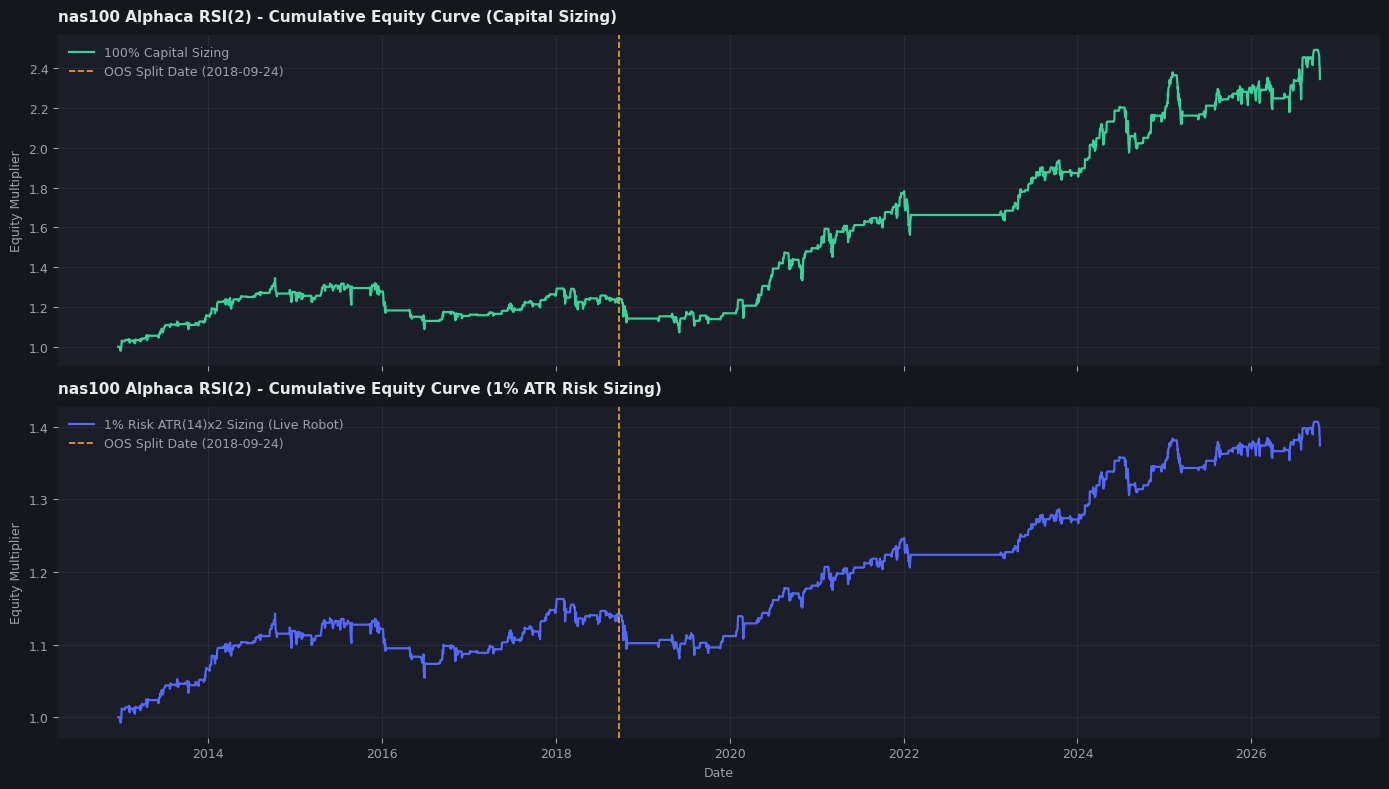

In [4]:
# Run backtest with frozen rules across IS, OOS, and Full Dataset
trades_is  = eng.run_rsi2_backtest(df_is,  rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
trades_oos = eng.run_rsi2_backtest(df_oos, rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
trades_all = eng.run_rsi2_backtest(df,     rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)

def format_perf_table(t_df, period_name, price_df):
    m_cap = compute_metrics(t_df, contract_multiplier=1.0, cost_per_trade=0.0)
    t_atr = t_df.assign(pnl=t_df['pnl_atr'], win=t_df['pnl_atr'] > 0)
    m_atr = compute_metrics(t_atr, contract_multiplier=1.0, cost_per_trade=0.0)

    ret_cap = eng.daily_returns(price_df, t_df, sizing="capital")
    ret_atr = eng.daily_returns(price_df, t_df, sizing="atr")

    eq_cap = (1.0 + ret_cap).cumprod()
    eq_atr = (1.0 + ret_atr).cumprod()

    return pd.DataFrame([
        {
            'Period': period_name,
            'Sizing': '100% Capital',
            'Trades': m_cap['num_trades'],
            'Win Rate': f"{m_cap['win_rate']:.1f}%",
            'Profit Factor': f"{m_cap['profit_factor']:.3f}",
            'Expectancy': f"{m_cap['expectancy']:.3f}%",
            'Total Return': f"{(eq_cap.iloc[-1] - 1)*100:.1f}%",
            'Sharpe': f"{sharpe_ratio(ret_cap):.2f}",
            'Max Drawdown': f"{max_drawdown(eq_cap)*100:.2f}%"
        },
        {
            'Period': period_name,
            'Sizing': '1% ATR Risk',
            'Trades': m_atr['num_trades'],
            'Win Rate': f"{m_atr['win_rate']:.1f}%",
            'Profit Factor': f"{m_atr['profit_factor']:.3f}",
            'Expectancy': f"{m_atr['expectancy']:.3f}%",
            'Total Return': f"{(eq_atr.iloc[-1] - 1)*100:.1f}%",
            'Sharpe': f"{sharpe_ratio(ret_atr):.2f}",
            'Max Drawdown': f"{max_drawdown(eq_atr)*100:.2f}%"
        }
    ])

perf_table = pd.concat([
    format_perf_table(trades_is,  f"In-Sample ({df_is.index[0].year}-{df_is.index[-1].year})", df_is),
    format_perf_table(trades_oos, f"Out-of-Sample ({df_oos.index[0].year}-{df_oos.index[-1].year})", df_oos),
    format_perf_table(trades_all, f"Full Period ({df.index[0].year}-{df.index[-1].year})", df)
], ignore_index=True)

print("=" * 80)
print(f"PERFORMANCE SUMMARY (NET OF {SLIP_BPS:g} BPS SLIPPAGE PER SIDE)")
print("=" * 80)
display(perf_table)

# Plot Equity Curves
ret_cap_all = eng.daily_returns(df, trades_all, sizing="capital")
ret_atr_all = eng.daily_returns(df, trades_all, sizing="atr")
eq_cap_all = (1.0 + ret_cap_all).cumprod()
eq_atr_all = (1.0 + ret_atr_all).cumprod()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, facecolor='#15171c')
for ax in (ax1, ax2):
    ax.set_facecolor('#1b1e26')
    ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(colors='#9aa0ab', labelsize=9)

split_label = f"OOS Split Date ({oos_start:%Y-%m-%d})"

ax1.plot(df.index, eq_cap_all, color='#34d399', lw=1.6, label='100% Capital Sizing')
ax1.axvline(oos_start, color='#f5a524', ls='--', lw=1.2, label=split_label)
ax1.set_title(f'{TICKER} Alphaca RSI(2) - Cumulative Equity Curve (Capital Sizing)', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left', pad=10)
ax1.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax1.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

ax2.plot(df.index, eq_atr_all, color='#5468ff', lw=1.6, label='1% Risk ATR(14)x2 Sizing (Live Robot)')
ax2.axvline(oos_start, color='#f5a524', ls='--', lw=1.2, label=split_label)
ax2.set_title(f'{TICKER} Alphaca RSI(2) - Cumulative Equity Curve (1% ATR Risk Sizing)', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left', pad=10)
ax2.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax2.set_xlabel('Date', color='#9aa0ab', fontsize=9)
ax2.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

## 5. SANITY CHECKS & VERIFICATION

In [5]:
print("=" * 70)
print("SANITY CHECKS & REPRODUCIBILITY")
print("=" * 70)

# 1. Assert No Lookahead Bias and index alignment
# entry_time must be strictly after the signal bar, and i_ent / i_sal must point
# to the correct rows of df.
for idx, row in trades_all.iterrows():
    signal_time = df.index[row['i_ent'] - 1]
    entry_time = row['entry_time']
    assert entry_time > signal_time, f"Lookahead detected at trade {idx}!"
    assert df.index[int(row['i_ent'])] == entry_time, f"i_ent misaligned at trade {idx}!"
    assert df.index[int(row['i_sal'])] == row['exit_time'], f"i_sal misaligned at trade {idx}!"
    expected_open = df.loc[entry_time, 'open'] * (1.0 + SLIP)
    assert np.isclose(row['entry_price'], expected_open, atol=1e-4), f"Entry price mismatch at trade {idx}!"

print(f"Sanity Check 1: PASSED. Strictly zero lookahead bias verified across all {len(trades_all)} trades.")
print("   - Signal evaluated at close of day t-1.")
print(f"   - Execution at open of day t with +{SLIP_BPS:.0f} bps slippage applied.")
print("   - i_ent / i_sal aligned with the price DataFrame.")

# 2. Trade Distribution per Calendar Year
trades_all['year'] = pd.to_datetime(trades_all['entry_time']).dt.year
trades_per_year = trades_all.groupby('year').size()

print("\nSanity Check 2: Trade Frequency per Year:")
print(f"   - Average trades per year: {trades_per_year.mean():.1f}")
print(f"   - Min trades: {trades_per_year.min()} ({trades_per_year.idxmin()}) | Max trades: {trades_per_year.max()} ({trades_per_year.idxmax()})")

# 3. Cross-Check with Alphaca Reference Benchmark (only applies to 15/200/2green reference rules)
is_reference = (TICKER, RSI_THR, SMA_LEN, EXIT_MODE) == ("QQQ", 15.0, 200, "2green")
tis_ref_path = "/Users/luyandy/Downloads/TIS-RSI2-Research-main/resultados/metricas.json"

if not is_reference:
    print("\nSanity Check 3: skipped (not reference rules 15/200/2green).")
elif os.path.exists(tis_ref_path):
    with open(tis_ref_path) as f:
        tis_data = json.load(f)
    tis_is = tis_data['fase1']['IS']
    tis_oos = tis_data['fase1']['OOS']

    comp_df = pd.DataFrame([
        {
            'Metric': 'In-Sample Trades (N)',
            'Engine (Ours)': len(trades_is),
            'TIS Benchmark': tis_is['n'],
            'Match': len(trades_is) == tis_is['n']
        },
        {
            'Metric': 'In-Sample Profit Factor',
            'Engine (Ours)': f"{compute_metrics(trades_is, 1.0)['profit_factor']:.3f}",
            'TIS Benchmark': f"{tis_is['pf']:.3f}",
            'Match': np.isclose(compute_metrics(trades_is, 1.0)['profit_factor'], tis_is['pf'], atol=1e-3)
        },
        {
            'Metric': 'Out-of-Sample Trades (N)',
            'Engine (Ours)': len(trades_oos),
            'TIS Benchmark': tis_oos['n'],
            'Match': len(trades_oos) == tis_oos['n']
        },
        {
            'Metric': 'Out-of-Sample Profit Factor',
            'Engine (Ours)': f"{compute_metrics(trades_oos, 1.0)['profit_factor']:.3f}",
            'TIS Benchmark': f"{tis_oos['pf']:.3f}",
            'Match': np.isclose(compute_metrics(trades_oos, 1.0)['profit_factor'], tis_oos['pf'], atol=1e-3)
        }
    ])
    print("\nSanity Check 3: Comparison with Alphaca Reference Benchmark:")
    display(comp_df)
else:
    print("\nSanity Check 3: Alphaca benchmark file not found at expected location.")

SANITY CHECKS & REPRODUCIBILITY
Sanity Check 1: PASSED. Strictly zero lookahead bias verified across all 212 trades.
   - Signal evaluated at close of day t-1.
   - Execution at open of day t with +5 bps slippage applied.
   - i_ent / i_sal aligned with the price DataFrame.

Sanity Check 2: Trade Frequency per Year:
   - Average trades per year: 14.1
   - Min trades: 1 (2012) | Max trades: 22 (2023)

Sanity Check 3: skipped (not reference rules 15/200/2green).


## 6. REFERENCE VARIANT: CONNORS BOOK RULES VS. ALPHACA RULES

VARIANT COMPARISON: Alphaca RULES VS. CONNORS BOOK RULES


,Strategy Variant,Trades,Win Rate,Profit Factor,Expectancy,Avg Holding (Bars),Sharpe,Max Drawdown
0,"Alphaca Version (RSI<20, SMA=230, 2 Green Cand...",212,72.6%,1.797,0.424%,4.8,0.60,-20.29%
1,"Connors Book Version (RSI<5, Close>MA5 Exit)",62,69.4%,2.488,0.548%,3.3,0.42,-8.41%


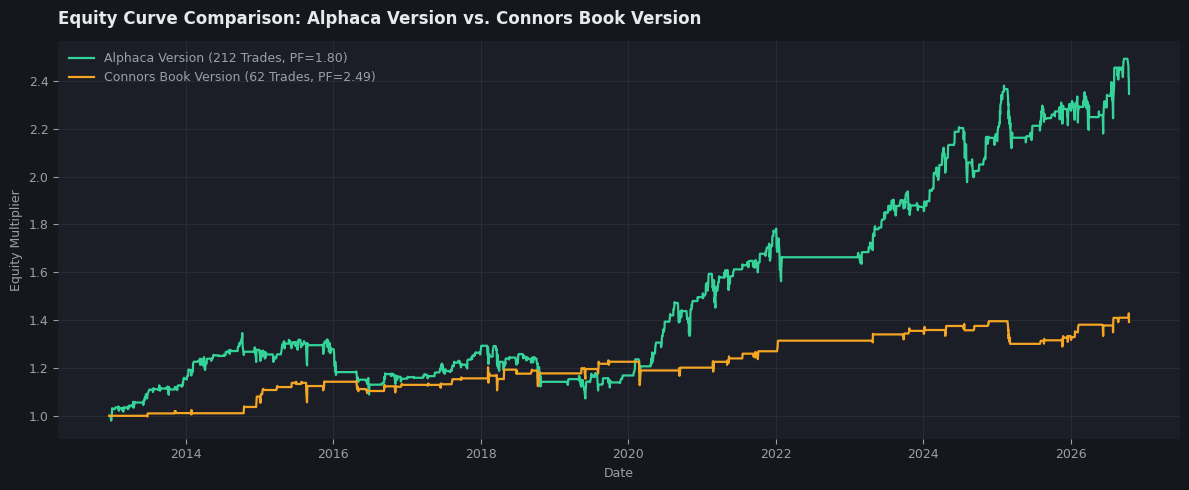

In [6]:
# Connors Original Book Rules: RSI(2) <= 5, Exit on Close > MA(5), Close > SMA(200)
df_connors = eng.prepare(df_raw, sma_len=200)
df_connors = df_connors[df_connors.index >= df.index[0]]
trades_connors = eng.run_rsi2_backtest(df_connors, rsi_thr=5.0, sma_len=200, exit_mode="ma5", slip_bps_per_side=SLIP_BPS)

m_tis = compute_metrics(trades_all, 1.0, 0.0)
m_con = compute_metrics(trades_connors, 1.0, 0.0)

ret_tis = eng.daily_returns(df, trades_all, "capital")
ret_con = eng.daily_returns(df_connors, trades_connors, "capital")
eq_tis = (1 + ret_tis).cumprod()
eq_con = (1 + ret_con).cumprod()

comp_variants = pd.DataFrame([
    {
        'Strategy Variant': f"Alphaca Version (RSI<{RSI_THR:g}, SMA={SMA_LEN}, 2 Green Candles Exit)",
        'Trades': m_tis['num_trades'],
        'Win Rate': f"{m_tis['win_rate']:.1f}%",
        'Profit Factor': f"{m_tis['profit_factor']:.3f}",
        'Expectancy': f"{m_tis['expectancy']:.3f}%",
        'Avg Holding (Bars)': f"{trades_all['bars'].mean():.1f}",
        'Sharpe': f"{sharpe_ratio(ret_tis):.2f}",
        'Max Drawdown': f"{max_drawdown(eq_tis)*100:.2f}%"
    },
    {
        'Strategy Variant': 'Connors Book Version (RSI<5, Close>MA5 Exit)',
        'Trades': m_con['num_trades'],
        'Win Rate': f"{m_con['win_rate']:.1f}%",
        'Profit Factor': f"{m_con['profit_factor']:.3f}",
        'Expectancy': f"{m_con['expectancy']:.3f}%",
        'Avg Holding (Bars)': f"{trades_connors['bars'].mean():.1f}",
        'Sharpe': f"{sharpe_ratio(ret_con):.2f}",
        'Max Drawdown': f"{max_drawdown(eq_con)*100:.2f}%"
    }
])

print("=" * 80)
print("VARIANT COMPARISON: Alphaca RULES VS. CONNORS BOOK RULES")
print("=" * 80)
display(comp_variants)

# Visual Comparison of Variants
fig, ax = plt.subplots(figsize=(12, 5), facecolor='#15171c')
ax.set_facecolor('#1b1e26')
ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(colors='#9aa0ab', labelsize=9)

ax.plot(df.index, eq_tis, color='#34d399', lw=1.6,
        label=f"Alphaca Version ({m_tis['num_trades']} Trades, PF={m_tis['profit_factor']:.2f})")
ax.plot(df_connors.index, eq_con, color='#f5a524', lw=1.6,
        label=f"Connors Book Version ({m_con['num_trades']} Trades, PF={m_con['profit_factor']:.2f})")
ax.set_title('Equity Curve Comparison: Alphaca Version vs. Connors Book Version', color='#e8e9ec', fontweight='bold', fontsize=12, loc='left', pad=12)
ax.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax.set_xlabel('Date', color='#9aa0ab', fontsize=9)
ax.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

## 6.5 COMPARISON

In [7]:
BASE_RSI, BASE_SMA = 15.0, 200

df_base_full = eng.prepare(df_raw, sma_len=BASE_SMA)
start = max(df.index[0], df_base_full.index[0])
d_cfg = df[df.index >= start]
d_base = df_base_full[df_base_full.index >= start]
assert d_cfg.index.equals(d_base.index), "Date index mismatch between comparison series."

t_cfg = eng.run_rsi2_backtest(d_cfg, rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
t_base = eng.run_rsi2_backtest(d_base, rsi_thr=BASE_RSI, sma_len=BASE_SMA, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)

r_cfg = eng.daily_returns(d_cfg, t_cfg, sizing="atr")
r_base = eng.daily_returns(d_base, t_base, sizing="atr")
eq_cfg, eq_base = (1 + r_cfg).cumprod(), (1 + r_base).cumprod()

def _row(name, t, r, eq):
    m = compute_metrics(t, 1.0, 0.0)
    return {'Variant': name, 'Trades': m['num_trades'], 'Win Rate': f"{m['win_rate']:.1f}%",
            'Profit Factor': f"{m['profit_factor']:.3f}", 'Sharpe': f"{sharpe_ratio(r):.2f}",
            'Max Drawdown': f"{max_drawdown(eq)*100:.2f}%"}

print("=" * 80)
print(f"CONFIGURED ({RSI_THR:g}/{SMA_LEN}) vs BASELINE ({BASE_RSI:g}/{BASE_SMA})  |  common window: "
      f"{d_cfg.index[0]:%Y-%m-%d} to {d_cfg.index[-1]:%Y-%m-%d}  |  sizing ATR")
print("=" * 80)
display(pd.DataFrame([_row(f"Configured ({RSI_THR:g}/{SMA_LEN})", t_cfg, r_cfg, eq_cfg),
                      _row(f"Baseline ({BASE_RSI:g}/{BASE_SMA})", t_base, r_base, eq_base)]))

in_cfg, in_base = (r_cfg != 0), (r_base != 0)
print(f"Daily returns correlation             : {r_cfg.corr(r_base):.3f}")
print(f"Configured entries matching baseline  : {t_cfg['entry_time'].isin(t_base['entry_time']).mean():.0%}")
print(f"Baseline entries matching configured  : {t_base['entry_time'].isin(t_cfg['entry_time']).mean():.0%}")
print(f"Configured exits matching baseline    : {t_cfg['exit_time'].isin(t_base['exit_time']).mean():.0%}")
print(f"Days in position shared between both  : "
      f"{(in_cfg & in_base).sum() / max(in_cfg.sum(), 1):.0%}")

CONFIGURED (20/230) vs BASELINE (15/200)  |  common window: 2012-12-18 to 2026-10-16  |  sizing ATR


,Variant,Trades,Win Rate,Profit Factor,Sharpe,Max Drawdown
0,Configured (20/230),212,72.6%,1.797,0.58,-7.74%
1,Baseline (15/200),167,74.3%,1.907,0.56,-7.14%


Daily returns correlation             : 0.918
Configured entries matching baseline  : 57%
Baseline entries matching configured  : 72%
Configured exits matching baseline    : 78%
Days in position shared between both  : 79%


## 7. SUMMARY OF HYPOTHESIS & NEXT STEPS

In [8]:

m_all   = compute_metrics(trades_all, 1.0, 0.0)  
m_is    = compute_metrics(trades_is,  1.0, 0.0)
m_oos   = compute_metrics(trades_oos, 1.0, 0.0)

max_dd_atr = max_drawdown(eq_atr_all) * 100          
years      = (df.index[-1] - df.index[0]).days / 365.25

ticker  = TICKER
ATR_LEN, ATR_MULT, RISK_PCT = 14, 2, 1
next_nb = "02_RSI2_Optimization.ipynb"

confirmed = m_all["profit_factor"] > 1.5 and m_all["win_rate"] > 55
verdict   = "Hypothesis Confirmed" if confirmed else "Hypothesis NOT clearly confirmed"

if "is_reference" in globals() and is_reference and "tis_is" in globals():
    repro = (f"Our implementation vs Alphaca reference benchmark "
             f"({len(trades_is)} vs {tis_is['n']} IS trades, PF={m_is['profit_factor']:.3f} vs {tis_is['pf']:.3f}; "
             f"{len(trades_oos)} vs {tis_oos['n']} OOS trades, PF={m_oos['profit_factor']:.3f} vs {tis_oos['pf']:.3f}).")
else:
    repro = (f"Alphaca benchmark comparison not applicable (configured {RSI_THR:g}/{SMA_LEN} differs from reference 15/200). "
             f"Results here: {len(trades_is)} IS trades with PF={m_is['profit_factor']:.3f}; "
             f"{len(trades_oos)} OOS trades with PF={m_oos['profit_factor']:.3f}.")

print("=" * 80)
print("7. SUMMARY OF HYPOTHESIS & NEXT STEPS")
print("=" * 80)
print(f"""
Key Findings:

1. {verdict}: Buying short-term pullbacks (RSI(2) < {RSI_THR:g}) in an uptrend (Close > SMA({SMA_LEN})) yields {'a strong' if confirmed else 'a weak'} edge on {ticker} with a {m_all['win_rate']:.1f}% win rate and Profit Factor of {m_all['profit_factor']:.3f} across {years:.0f}+ years ({m_all['num_trades']} trades).

2. Robustness of ATR Sizing: The {RISK_PCT}% risk ATR({ATR_LEN})x{ATR_MULT} sizing model keeps maximum drawdown at {max_dd_atr:.2f}% over the entire {df.index[0].year}-{df.index[-1].year} span.

3. Reproducibility: {repro}

4. Next Step: Proceed to {next_nb} to evaluate parameter sensitivity and verify that (RSI(2) < {RSI_THR:g}, {SMA_LEN}) sits on a broad, stable parameter plateau on in-sample data.
""")

7. SUMMARY OF HYPOTHESIS & NEXT STEPS

Key Findings:

1. Hypothesis Confirmed: Buying short-term pullbacks (RSI(2) < 20) in an uptrend (Close > SMA(230)) yields a strong edge on nas100 with a 72.6% win rate and Profit Factor of 1.797 across 14+ years (212 trades).

2. Robustness of ATR Sizing: The 1% risk ATR(14)x2 sizing model keeps maximum drawdown at -7.74% over the entire 2012-2026 span.

3. Reproducibility: Alphaca benchmark comparison not applicable (configured 20/230 differs from reference 15/200). Results here: 87 IS trades with PF=1.530; 125 OOS trades with PF=1.946.

4. Next Step: Proceed to 02_RSI2_Optimization.ipynb to evaluate parameter sensitivity and verify that (RSI(2) < 20, 230) sits on a broad, stable parameter plateau on in-sample data.



## 8. SAVE THE RESULTS OF THIS NOTEBOOK FOR THE VARIANT

In [9]:
save_json(cfg, "01_hypothesis.json", {
    "variant": cfg["id"],
    "ticker": TICKER,
    "params": cfg["params"],
    "oos_start": str(oos_start.date()),
    "all": {"n": int(len(trades_all)), "pf": float(m_all["profit_factor"]), "win_rate": float(m_all["win_rate"])},
    "is":  {"n": int(len(trades_is)),  "pf": float(m_is["profit_factor"])},
    "oos": {"n": int(len(trades_oos)), "pf": float(m_oos["profit_factor"])},
    "max_dd_atr_pct": float(max_dd_atr),
    "hypothesis_confirmed": bool(confirmed),
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/RSI2/notebooks/RSI2/runs/v1_nas100/01_hypothesis.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/RSI2/notebooks/RSI2/runs/v1_nas100/01_hypothesis.json')

## 9. SIGNAL PARITY

In [10]:
BASE_VARIANT = "base_nasdaq"   # base variant: yaml name without .yaml. In the base itself: None
if BASE_VARIANT:
    cb = load_variant(BASE_VARIANT)

    # Both runs use THIS variant's params (kw below), so the comparison stays valid.
    # Warn instead of stopping if the base YAML has different params.
    diff = {k: (cb["params"].get(k), cfg["params"].get(k))
            for k in set(cb["params"]) | set(cfg["params"])
            if cb["params"].get(k) != cfg["params"].get(k)}
    if diff:
        print("WARNING: base params differ from this variant (base, variant). "
              "Both backtests below use the VARIANT params:")
        for k, (bv, vv) in sorted(diff.items()):
            print(f"  {k}: {bv} vs {vv}")

    rb = eng.load_data(cb["instrument"]["ticker"], start=DATA_START, source="yahoo")
    idx = rb.index.intersection(df_raw.index)
    b, v = rb.loc[idx], df_raw.loc[idx]
    db, dv = eng.prepare(b, SMA_LEN), eng.prepare(v, SMA_LEN)
    kw = dict(rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
    tb = eng.run_rsi2_backtest(db, financing_bps_per_night=0.0, **kw)
    tv = eng.run_rsi2_backtest(dv, **kw)

    def match(a, c):
        """Share of positions in `a` that have a match in `c` within +-1 bar."""
        a, c = np.asarray(a), np.asarray(c)
        return float(np.mean([np.abs(c - x).min() <= 1 for x in a])) if len(a) and len(c) else 0.0

    def col(t, name):
        return t[name].values if len(t) else np.array([])

    span = rb.loc[df_raw.index[0]:df_raw.index[-1]]
    print(f"extra days: {len(df_raw.index.difference(rb.index))} | missing: {len(span.index.difference(df_raw.index))}")
    print(f"corr: {b.close.pct_change().corr(v.close.pct_change()):.4f} | "
          f"green: {((b.close > b.open) == (v.close > v.open)).mean():.2%}")
    print(f"trades base/variant: {len(tb)}/{len(tv)} | "
          f"entries match: {min(match(col(tv, 'i_ent'), col(tb, 'i_ent')), match(col(tb, 'i_ent'), col(tv, 'i_ent'))):.0%} | "
          f"exits match: {min(match(col(tv, 'i_sal'), col(tb, 'i_sal')), match(col(tb, 'i_sal'), col(tv, 'i_sal'))):.0%}")

extra days: 0 | missing: 13
corr: 0.9981 | green: 96.91%
trades base/variant: 209/212 | entries match: 95% | exits match: 95%


In [11]:
import datetime as dt

def pf(t, col="pnl"):
    p = t[col].values
    g, l = p[p > 0].sum(), -p[p < 0].sum()
    return g / l if l > 0 else np.inf

kw = dict(rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)

# ---- A) Data vs swap: mismos días, mismos parámetros ----
rows = []
for name, raw in [("Yahoo ^NDX", b), ("CFD nas100", v)]:
    d = eng.prepare(raw, SMA_LEN)
    for swap in (0.0, 2.0):
        t = eng.run_rsi2_backtest(d, financing_bps_per_night=swap, **kw)
        oos = t[t["entry_time"] >= pd.Timestamp(OOS_START)]
        rows.append({"data": name, "swap": swap, "N": len(t), "win%": 100 * t["win"].mean(),
                     "PF": pf(t), "exp%": t["pnl"].mean(), "PF_OOS": pf(oos),
                     "exp%_OOS": oos["pnl"].mean(), "avg_nights": t["nights"].mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ---- B) Qué tan distintas son las dos series ----
dc = (v.close / b.close - 1) * 1e4
do = (v.open / b.open - 1) * 1e4
gb = (b.open / b.close.shift() - 1) * 1e4
gv = (v.open / v.close.shift() - 1) * 1e4
print(pd.DataFrame({"close diff": dc.describe(), "open diff": do.describe(),
                    "gap Yahoo": gb.describe(), "gap CFD": gv.describe()}).round(2))
body = (b.close / b.open - 1).abs() * 1e4
flip = (b.close > b.open) != (v.close > v.open)
print("\nflip rate por quintil de |cuerpo|:\n", flip.groupby(pd.qcut(body, 5)).mean().round(3))
print("\npeores diferencias de close (bps):\n", dc.abs().sort_values(ascending=False).head(15).round(1))
print("\ndiferencia media de open por año (bps):\n", do.groupby(do.index.year).mean().round(1))

# ---- C) Test de zona horaria / sesión ----
def shift(hhmm, h):
    return (dt.datetime.strptime(hhmm, "%H:%M") + dt.timedelta(hours=h)).strftime("%H:%M")

res = []
for h in range(-3, 4):
    dd = eng._clean_bars(eng._build_session_daily(
        str(eng.ENGINE_DEFAULTS["csv_path"]), eng.ENGINE_DEFAULTS["session_tz"],
        shift("09:30", h), shift("16:00", h)))
    ix = rb.index.intersection(dd.index)
    res.append({"shift_h": h, "days": len(ix),
                "corr_ret": rb.close.loc[ix].pct_change().corr(dd.close.loc[ix].pct_change()),
                "green_match": ((rb.close.loc[ix] > rb.open.loc[ix]) ==
                                (dd.close.loc[ix] > dd.open.loc[ix])).mean()})
print(pd.DataFrame(res).round(4).to_string(index=False))

      data  swap   N   win%    PF  exp%  PF_OOS  exp%_OOS  avg_nights
Yahoo ^NDX   0.0 209 72.727 2.179 0.601   2.313     0.732       7.029
Yahoo ^NDX   2.0 209 69.856 1.813 0.460   1.999     0.601       7.029
CFD nas100   0.0 212 74.057 2.185 0.565   2.270     0.666       7.042
CFD nas100   2.0 212 72.642 1.797 0.424   1.946     0.536       7.042
       close diff  open diff  gap Yahoo  gap CFD
count     3695.00    3695.00    3694.00  3694.00
mean        -1.03      -1.69       4.44     3.76
std          5.95      14.96      80.05    79.85
min       -106.06    -540.30    -834.23 -1071.33
25%         -2.90      -5.96     -28.25   -29.03
50%         -0.91      -1.38       7.57     6.30
75%          0.93       2.52      41.69    40.12
max        103.17     388.22     577.38   602.89

flip rate por quintil de |cuerpo|:
 (0.06369999999999999, 17.466]    0.138
(17.466, 39.103]                 0.011
(39.103, 66.654]                 0.000
(66.654, 115.283]                0.005
(115.283, 1185.1

In [12]:
# ---- A2) ¿Se cierra el hueco con salidas que no dependen del open? (swap 0 a propósito) ----
rows = []
for exit_m in ("2green", "ma5", "rsi70"):
    for name, raw in [("Yahoo ^NDX", b), ("CFD nas100", v)]:
        d = eng.prepare(raw, SMA_LEN)
        t = eng.run_rsi2_backtest(d, rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=exit_m,
                                  slip_bps_per_side=SLIP_BPS, financing_bps_per_night=0.0)
        oos = t[t["entry_time"] >= pd.Timestamp(OOS_START)]
        rows.append({"exit": exit_m, "data": name, "N": len(t), "win%": 100 * t["win"].mean(),
                     "PF": pf(t), "exp%": t["pnl"].mean(), "PF_OOS": pf(oos),
                     "exp%_OOS": oos["pnl"].mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ---- D) Calidad de barras intradía: ¿por qué falla el close en 2013? ----
raw_i = pd.read_csv(eng.ENGINE_DEFAULTS["csv_path"])
raw_i.columns = [str(c).strip().lower() for c in raw_i.columns]
tcol = next(c for c in ("time", "date", "datetime", "timestamp") if c in raw_i.columns)
tt_ = raw_i[tcol]
ts = (pd.to_datetime(tt_, unit="ms", utc=True) if pd.api.types.is_numeric_dtype(tt_)
      else pd.to_datetime(tt_, utc=True))
raw_i.index = pd.DatetimeIndex(ts.dt.tz_convert(eng.ENGINE_DEFAULTS["session_tz"]))
ses = raw_i.between_time("09:30", "16:00", inclusive="left")
ses = ses[ses.index.dayofweek < 5]
day = ses.index.tz_localize(None).normalize()
tt = ses.index.to_series().groupby(day).agg(["first", "last", "size"])
tt["first"], tt["last"] = tt["first"].dt.strftime("%H:%M"), tt["last"].dt.strftime("%H:%M")
chk = tt.join(pd.DataFrame({"close_diff": dc, "open_diff": do}), how="inner")

print("Peores close_diff:\n", chk.reindex(dc.abs().sort_values(ascending=False).head(15).index).round(1))
print("\nPeores open_diff:\n", chk.reindex(do.abs().sort_values(ascending=False).head(15).index).round(1))
print("\nCalidad por año:\n", chk.groupby(chk.index.year).agg(
    bars_med=("size", "median"),
    late_first=("first", lambda s: (s > "09:35").mean()),
    early_last=("last", lambda s: (s < "15:30").mean())).round(3))

  exit       data   N   win%    PF  exp%  PF_OOS  exp%_OOS
2green Yahoo ^NDX 209 72.727 2.179 0.601   2.313     0.732
2green CFD nas100 212 74.057 2.185 0.565   2.270     0.666
   ma5 Yahoo ^NDX 224 72.321 2.306 0.499   2.408     0.599
   ma5 CFD nas100 227 71.366 2.250 0.486   2.278     0.565
 rsi70 Yahoo ^NDX 207 76.329 2.491 0.632   2.592     0.774
 rsi70 CFD nas100 206 75.243 2.481 0.609   2.463     0.714
Peores close_diff:
             first   last  size  close_diff  open_diff
time                                                 
2013-02-27  09:30  11:30     5      -106.1       -8.0
2013-04-18  09:30  10:30     3       103.2      -22.4
2020-03-16  09:30  15:30    13      -102.0     -540.3
2013-02-25  09:30  15:30    13        93.1     -105.0
2015-12-31  09:30  13:00     8        86.2        3.6
2014-12-31  09:30  14:00    10        85.7      -14.7
2020-03-18  09:30  15:30    13        64.9       37.3
2013-10-18  09:30  15:30    13       -64.5      -88.1
2013-02-26  09:30  15:30   